# MarketMind — Experiment 07: Walk-Forward Strategy Evaluation

## Objective
Test whether a market-regime model adds value to simple strategy selection on historical NIFTY 50 data.

This is a research backtest, not evidence of live profitability. The source data is an index series, not an executable futures/options instrument. Results are therefore an index-return proxy and depend on the explicit cost assumptions below.

## Evaluation design
- Resample 1-minute OHLC to 15-minute bars.
- Build causal OHLC-derived features.
- Use rolling chronological folds: 2 years training, 6 months validation, 3 months test; advance by 3 months.
- Fit preprocessing and KMeans regimes on training data only.
- Select the best simple strategy for each training-defined regime using validation data only.
- Evaluate that fixed mapping on the subsequent unseen test window.
- Compare with each standalone strategy and a validation-selected unconditional strategy.
- Execute signals at the next bar open and hold for one bar, within the same trading session.
- Apply configurable one-way transaction costs to position changes.

**Important:** No independent ground-truth regime labels exist. Cluster names are descriptive, not objectively verified market states. Internal cluster metrics are not strategy-performance metrics.

## 1. Setup and configuration

Run from the project root or from `research/`. The loader searches common project locations and allows a manual path override.

In [1]:
from pathlib import Path
import warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
N_CLUSTERS = 4

# Placeholder assumption, not broker-verified charges.
ONE_WAY_COST_BPS = 5.0

TRAIN_MONTHS = 24
VALIDATION_MONTHS = 6
TEST_MONTHS = 3
STEP_MONTHS = 3

# Optional: set to a folder containing the historical yearly/monthly 1-minute CSVs,
# or to one specific CSV file.
DATA_PATH_OVERRIDE = None

def find_data_files():
    if DATA_PATH_OVERRIDE:
        p = Path(DATA_PATH_OVERRIDE).expanduser()
        if not p.exists():
            raise FileNotFoundError(f"DATA_PATH_OVERRIDE does not exist: {p}")
        if p.is_file():
            return [p]
        files = sorted(p.glob("**/*.csv"))
        if not files:
            raise FileNotFoundError(f"No CSV files found under: {p}")
        return files

    here = Path.cwd()
    roots = [here, here.parent, here.parent.parent, Path("/mnt/data")]
    # Prefer the real historical repository structure, not the short Yahoo sample.
    for base in roots:
        candidates = [
            base / "data/raw/nifty50/1min",
            base / "MarketMind/data/raw/nifty50/1min",
        ]
        for folder in candidates:
            if folder.exists():
                files = sorted(folder.glob("**/*.csv"))
                if files:
                    return files

    # Fall back to a full historical 1-minute directory found beneath the workspace.
    for base in roots:
        matches = list(base.glob("**/nifty50/1min/**/*.csv"))
        if matches:
            return sorted(matches)

    # Last resort: the single Yahoo-format file (may be too short for walk-forward).
    for base in roots:
        for candidate in [
            base / "data/raw/nifty50_yahoo_1m.csv",
            base / "MarketMind/data/raw/nifty50_yahoo_1m.csv",
        ]:
            if candidate.exists():
                return [candidate]

    raise FileNotFoundError(
        "Could not find historical NIFTY 1-minute CSVs. Set DATA_PATH_OVERRIDE "
        "to the folder containing the yearly/monthly files."
    )

DATA_PATHS = find_data_files()
print(f"Found {len(DATA_PATHS)} CSV file(s)")
for p in DATA_PATHS[:5]:
    print(" -", p)
if len(DATA_PATHS) > 5:
    print(" - ...")


Found 20 CSV file(s)
 - D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min\2017\NIFTY50_1min_2017.csv
 - D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min\2018\NIFTY50_1min_2018.csv
 - D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min\2019\NIFTY50_1min_2019.csv
 - D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min\2020\NIFTY50_1min_2020.csv
 - D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min\2021\NIFTY50_1min_2021.csv
 - ...


## 2. Load and normalize OHLC data

The code handles common timestamp/column naming variants. Inspect the detected columns before continuing. The source should contain genuine historical observations; this notebook does not generate market data.

In [2]:
frames = []
for path in DATA_PATHS:
    part = pd.read_csv(path)
    # Keep only files that contain the required OHLC columns.
    cols = {str(c).strip().lower() for c in part.columns}
    if {"open", "high", "low", "close"}.issubset(cols):
        frames.append(part)

if not frames:
    raise ValueError("No CSV files with Open, High, Low, Close columns were found.")

raw = pd.concat(frames, ignore_index=True)
print("Combined raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())


Combined raw shape: (890728, 7)
Columns: ['Epoch', 'Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume']


,Epoch,Timestamp,Open,High,Low,Close,Volume
0,1491191100,2017-04-03T09:15:00,9219.63,9221.75,9202.90,9204.85,NaN
1,1491191160,2017-04-03T09:16:00,9205.60,9206.00,9201.45,9203.40,NaN
2,1491191220,2017-04-03T09:17:00,9204.25,9207.15,9203.25,9204.40,NaN
3,1491191280,2017-04-03T09:18:00,9205.40,9206.00,9202.55,9203.55,NaN
4,1491191340,2017-04-03T09:19:00,9203.25,9205.85,9202.25,9204.00,NaN


In [3]:
def normalize_ohlc(frame):
    df = frame.copy()
    lower = {str(c).strip().lower(): c for c in df.columns}

    time_candidates = ["datetime", "date", "timestamp", "time"]
    time_col = next((lower[x] for x in time_candidates if x in lower), None)
    if time_col is None:
        # Common Yahoo export: first column is Date/Datetime but may have a different label.
        time_col = df.columns[0]

    rename = {}
    for target, options in {
        "open": ["open"],
        "high": ["high"],
        "low": ["low"],
        "close": ["close", "adj close", "adj_close"],
    }.items():
        found = next((lower[x] for x in options if x in lower), None)
        if found is None:
            raise ValueError(f"Missing required {target} column. Available: {df.columns.tolist()}")
        rename[found] = target

    df = df.rename(columns=rename)
    df["timestamp"] = pd.to_datetime(df[time_col], errors="coerce")
    df = df.dropna(subset=["timestamp", "open", "high", "low", "close"])
    for c in ["open", "high", "low", "close"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["open", "high", "low", "close"])
    df = df.sort_values("timestamp").drop_duplicates("timestamp")
    df = df.set_index("timestamp")
    return df[["open", "high", "low", "close"]]

ohlc_1m = normalize_ohlc(raw)
print("Clean 1m rows:", len(ohlc_1m))
print("Range:", ohlc_1m.index.min(), "to", ohlc_1m.index.max())
display(ohlc_1m.head())

Clean 1m rows: 890728
Range: 2017-04-03 09:15:00 to 2026-11-17 15:29:00


,open,high,low,close
timestamp,,,,
2017-04-03 09:15:00,9219.63,9221.75,9202.90,9204.85
2017-04-03 09:16:00,9205.60,9206.00,9201.45,9203.40
2017-04-03 09:17:00,9204.25,9207.15,9203.25,9204.40
2017-04-03 09:18:00,9205.40,9206.00,9202.55,9203.55
2017-04-03 09:19:00,9203.25,9205.85,9202.25,9204.00


## 3. Resample to 15-minute bars and build causal features

Features use information available at or before each 15-minute close. Strategy signals are computed at the close and executed at the next bar open. The backtest below avoids carrying a one-bar position across calendar dates.

In [4]:
bars = ohlc_1m.resample("15min", origin="start_day", label="left", closed="left").agg(
    {"open":"first", "high":"max", "low":"min", "close":"last"}
)
counts = ohlc_1m["close"].resample("15min", origin="start_day", label="left", closed="left").count()
bars["minute_count"] = counts
bars = bars.dropna(subset=["open","high","low","close"])
# Keep bars with a meaningful amount of 1m source observations.
bars = bars[bars["minute_count"] >= 10].copy()
bars["session_date"] = bars.index.date

close = bars["close"]
high = bars["high"]
low = bars["low"]

bars["ret_1"] = np.log(close / close.shift(1))
bars["ret_5"] = np.log(close / close.shift(5))
bars["momentum_20"] = np.log(close / close.shift(20))
bars["volatility_20"] = bars["ret_1"].rolling(20, min_periods=20).std()
delta = close.diff()
gain = delta.clip(lower=0).rolling(14, min_periods=14).mean()
loss = (-delta.clip(upper=0)).rolling(14, min_periods=14).mean()
rs = gain / loss.replace(0, np.nan)
bars["rsi_14"] = 100 - (100 / (1 + rs))
ema_fast = close.ewm(span=12, adjust=False).mean()
ema_slow = close.ewm(span=26, adjust=False).mean()
bars["ema_gap"] = (ema_fast - ema_slow) / close
tr = pd.concat([
    high-low, (high-close.shift()).abs(), (low-close.shift()).abs()
], axis=1).max(axis=1)
bars["atr_pct"] = tr.rolling(14, min_periods=14).mean() / close

FEATURES = ["ret_5", "momentum_20", "volatility_20", "rsi_14", "ema_gap", "atr_pct"]
bars = bars.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES)
print("15m rows after features:", len(bars))
print("Range:", bars.index.min(), "to", bars.index.max())
display(bars[FEATURES].describe().T)

15m rows after features: 59347
Range: 2017-04-03 14:15:00 to 2026-11-17 15:15:00


,count,mean,std,min,25%,50%,75%,max
ret_5,59347.0,0.000084,0.004507,-0.114978,-0.001528,0.000132,0.001743,0.112626
momentum_20,59347.0,0.000338,0.009092,-0.139989,-0.003858,0.000613,0.004895,0.153282
volatility_20,59347.0,0.001540,0.001278,0.000234,0.000914,0.001256,0.001783,0.031302
rsi_14,59347.0,51.798211,19.131669,0.000000,37.476234,51.776131,66.367093,99.928622
ema_gap,59347.0,0.000104,0.002330,-0.040399,-0.000983,0.000230,0.001321,0.021349
atr_pct,59347.0,0.002021,0.001279,0.000534,0.001332,0.001744,0.002337,0.027245


## 4. Define strategy candidates and execution convention

Strategies are deliberately simple and transparent:
- Trend: follow 20-bar momentum when it exceeds a volatility-scaled threshold.
- Mean reversion: fade RSI extremes.
- Breakout: trade a close beyond the prior 20-bar range.

A signal at bar *t* is filled at the open of bar *t+1*. The position is held until the open of bar *t+2*. Costs are charged on changes in exposure. This is a simplified index-return proxy; it does not model futures basis, options Greeks, market impact, or exact exchange/broker charges.

In [5]:
def make_signals(frame):
    out = pd.DataFrame(index=frame.index)
    # Momentum threshold adapts to recent volatility; avoid division by zero.
    vol = frame["volatility_20"].replace(0, np.nan)
    strength = frame["momentum_20"] / (vol * np.sqrt(20))
    out["trend"] = np.where(strength > 0.5, 1, np.where(strength < -0.5, -1, 0))

    rsi = frame["rsi_14"]
    out["mean_reversion"] = np.where(rsi < 30, 1, np.where(rsi > 70, -1, 0))

    prior_high = frame["high"].shift(1).rolling(20, min_periods=20).max()
    prior_low = frame["low"].shift(1).rolling(20, min_periods=20).min()
    out["breakout"] = np.where(frame["close"] > prior_high, 1,
                        np.where(frame["close"] < prior_low, -1, 0))
    return out.fillna(0).astype(int)

STRATEGIES = ["trend", "mean_reversion", "breakout"]
signals = make_signals(bars)

# Return from next session bar open to the following bar open.
next_open = bars.groupby("session_date")["open"].shift(-1)
next2_open = bars.groupby("session_date")["open"].shift(-2)
gross_market_return = (next2_open / next_open) - 1
gross_market_return.name = "next_bar_open_to_open_return"

def net_strategy_returns(signal, market_return, cost_bps=ONE_WAY_COST_BPS):
    # signal is formed at close t and becomes the position for t+1 -> t+2.
    pos = signal.astype(float)
    prev_pos = pos.groupby(pos.index.date).shift(1).fillna(0)
    turnover = (pos - prev_pos).abs()
    cost = turnover * (cost_bps / 10000.0)
    net = pos * market_return - cost
    return net, turnover

strategy_returns = pd.DataFrame(index=bars.index)
for name in STRATEGIES:
    strategy_returns[name], _ = net_strategy_returns(signals[name], gross_market_return)

valid_returns = gross_market_return.notna()
print("Bars with executable same-session next-bar returns:", int(valid_returns.sum()))

Bars with executable same-session next-bar returns: 54585


## 5. Rolling walk-forward fold construction

Each rolling fold uses:
1. Training window: fit scaler and KMeans; derive cluster descriptions.
2. Validation window: score each strategy within each training-defined cluster and choose the best strategy per cluster. Also choose the best unconditional strategy.
3. Test window: evaluate those fixed choices on unseen data.

Cluster IDs are arbitrary. The mapping is learned from validation outcomes, not by assigning semantic labels after looking at test returns.

In [6]:
dates = pd.Index(sorted(pd.unique(pd.to_datetime(bars["session_date"]))))
date_series = pd.Series(pd.to_datetime(bars["session_date"].values), index=bars.index)

def add_months(ts, months):
    return ts + pd.DateOffset(months=months)

folds = []
start = dates.min()
last = dates.max()
fold_start = start + pd.DateOffset(months=TRAIN_MONTHS + VALIDATION_MONTHS)
while fold_start < last:
    test_end = min(add_months(fold_start, TEST_MONTHS), last)
    train_start = fold_start - pd.DateOffset(months=TRAIN_MONTHS + VALIDATION_MONTHS)
    train_end = fold_start - pd.DateOffset(months=VALIDATION_MONTHS)
    val_start = train_end
    val_end = fold_start
    train_mask = (date_series < train_end) & (date_series >= train_start)
    val_mask = (date_series >= val_start) & (date_series < val_end)
    test_mask = (date_series >= fold_start) & (date_series < test_end)
    if train_mask.sum() > 500 and val_mask.sum() > 100 and test_mask.sum() > 100:
        folds.append((train_mask, val_mask, test_mask, train_start, train_end, val_start, val_end, fold_start, test_end))
    fold_start = add_months(fold_start, STEP_MONTHS)

print("Walk-forward folds:", len(folds))
if not folds:
    available_months = (last.year - start.year) * 12 + (last.month - start.month)
    raise RuntimeError(
        f"No valid folds. Data spans only about {available_months} calendar months "
        f"({start.date()} to {last.date()}). Current requirement is approximately "
        f"{TRAIN_MONTHS + VALIDATION_MONTHS + TEST_MONTHS} months per first fold. "
        "Check that the full historical 1-minute CSV folder was loaded."
    )

Walk-forward folds: 29


In [7]:
def summarize_returns(r):
    r = pd.Series(r).dropna()
    if len(r) == 0:
        return {"observations": 0, "total_return_pct": np.nan, "annualized_sharpe": np.nan,
                "max_drawdown_pct": np.nan, "win_rate_pct": np.nan, "profit_factor": np.nan}
    equity = (1 + r).cumprod()
    peak = equity.cummax()
    drawdown = equity / peak - 1
    # 15m bars; approximate 25 bars/session x 252 sessions.
    periods_per_year = 25 * 252
    std = r.std(ddof=1)
    sharpe = (r.mean() / std * np.sqrt(periods_per_year)) if std and np.isfinite(std) else np.nan
    gains = r[r > 0].sum()
    losses = -r[r < 0].sum()
    pf = gains / losses if losses > 0 else np.nan
    return {
        "observations": len(r),
        "total_return_pct": (equity.iloc[-1] - 1) * 100,
        "annualized_sharpe": sharpe,
        "max_drawdown_pct": drawdown.min() * 100,
        "win_rate_pct": (r > 0).mean() * 100,
        "profit_factor": pf
    }

## 6. Run the walk-forward experiment

The test set is never used to choose the regime-to-strategy mapping. If a cluster has too few validation observations, it falls back to the unconditional validation winner.

In [8]:
from sklearn.exceptions import ConvergenceWarning

fold_outputs = []
fold_mappings = []
fold_cluster_profiles = []

for fold_id, item in enumerate(folds, start=1):
    train_mask, val_mask, test_mask, tr0, tr1, va0, va1, te0, te1 = item

    X_train = bars.loc[train_mask, FEATURES]
    X_val = bars.loc[val_mask, FEATURES]
    X_test = bars.loc[test_mask, FEATURES]

    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xva = scaler.transform(X_val)
    Xte = scaler.transform(X_test)

    model = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=20)
    train_states = model.fit_predict(Xtr)
    val_states = model.predict(Xva)
    test_states = model.predict(Xte)

    train_state_series = pd.Series(train_states, index=X_train.index)
    val_state_series = pd.Series(val_states, index=X_val.index)
    test_state_series = pd.Series(test_states, index=X_test.index)

    # Describe states using training-only feature means. These labels are descriptive only.
    profile = X_train.copy()
    profile["state"] = train_states
    profile = profile.groupby("state")[FEATURES].mean()
    profile["train_occupancy_pct"] = train_state_series.value_counts(normalize=True).reindex(profile.index).fillna(0)*100
    profile["fold"] = fold_id
    fold_cluster_profiles.append(profile.reset_index())

    # Validation selection: evaluate all candidates within each state.
    val_perf = {}
    for strat in STRATEGIES:
        rr, _ = net_strategy_returns(signals.loc[X_val.index, strat], gross_market_return.loc[X_val.index])
        val_perf[strat] = rr

    unconditional_scores = {
        s: summarize_returns(val_perf[s])["annualized_sharpe"] for s in STRATEGIES
    }
    unconditional_winner = max(unconditional_scores, key=lambda s: (-np.inf if not np.isfinite(unconditional_scores[s]) else unconditional_scores[s]))

    mapping = {}
    for state in range(N_CLUSTERS):
        state_idx = X_val.index[val_state_series.values == state]
        if len(state_idx) < 50:
            mapping[state] = unconditional_winner
            continue
        scores = {}
        for strat in STRATEGIES:
            state_r = val_perf[strat].loc[state_idx]
            score = summarize_returns(state_r)["annualized_sharpe"]
            scores[strat] = score
        mapping[state] = max(scores, key=lambda s: (-np.inf if not np.isfinite(scores[s]) else scores[s]))

    # Apply fixed mapping to test. Also compute standalone and unconditional test returns.
    test_strategy = pd.Series(index=X_test.index, dtype=object)
    for state, strat in mapping.items():
        test_strategy.loc[test_state_series[test_state_series == state].index] = strat

    # One continuous position stream is essential: charge turnover both when
    # the chosen strategy changes and when its signal changes.
    regime_signal = pd.Series(0, index=X_test.index, dtype=int)
    for strat in STRATEGIES:
        idx = test_strategy[test_strategy == strat].index
        if len(idx):
            regime_signal.loc[idx] = signals.loc[idx, strat]
    regime_net, _ = net_strategy_returns(regime_signal, gross_market_return.loc[X_test.index])

    fold_returns = {
        "regime_selected": regime_net,
        "validation_selected_unconditional": val_perf[unconditional_winner].reindex(X_test.index),
    }
    for strat in STRATEGIES:
        rr, _ = net_strategy_returns(signals.loc[X_test.index, strat], gross_market_return.loc[X_test.index])
        fold_returns[strat] = rr

    for name, rr in fold_returns.items():
        stats = summarize_returns(rr)
        fold_outputs.append({
            "fold": fold_id, "strategy": name,
            "train_start": tr0, "train_end": tr1,
            "validation_start": va0, "validation_end": va1,
            "test_start": te0, "test_end": te1,
            **stats
        })

    fold_mappings.append({
        "fold": fold_id, "test_start": str(te0.date()), "test_end": str(te1.date()),
        "unconditional_validation_winner": unconditional_winner,
        "state_to_strategy": mapping,
        "validation_sharpe": unconditional_scores
    })

results = pd.DataFrame(fold_outputs)
mapping_df = pd.DataFrame(fold_mappings)
cluster_profiles = pd.concat(fold_cluster_profiles, ignore_index=True) if fold_cluster_profiles else pd.DataFrame()

display(results.groupby("strategy")[["total_return_pct","annualized_sharpe","max_drawdown_pct","win_rate_pct","profit_factor"]].agg(["mean","median","std"]).round(3))
display(mapping_df)

total_return_pct                 \
                                              mean  median    std   
strategy                                                            
breakout                                   -11.508 -11.258  2.612   
mean_reversion                             -11.002 -10.660  2.986   
regime_selected                             -9.667 -10.145  3.668   
trend                                       -8.788 -10.442  4.512   
validation_selected_unconditional              NaN     NaN    NaN   

                                  annualized_sharpe                 \
                                               mean  median    std   
strategy                                                             
breakout                                    -12.707 -12.612  4.618   
mean_reversion                               -8.521  -8.460  3.027   
regime_selected                              -6.506  -6.121  3.752   
trend                                        -5.131  -5.124  2.723   
validation_selected_unconditional               NaN     NaN    NaN   

                                  max_drawdown_pct                 \
                                              mean  median    std   
strategy                                                            
breakout                                   -11.897 -11.231  2.624   
mean_reversion                             -11.317 -10.945  2.952   
regime_selected                            -11.357 -11.912  3.558   
trend                                      -10.965 -11.912  3.546   
validation_selected_unconditional              NaN     NaN    NaN   

                                  win_rate_pct                profit_factor  \
                                          mean  median    std          mean   
strategy                                                                      
breakout                                 5.060   4.855  0.951         0.368   
mean_reversion                          15.306  15.428  1.545         0.624   
regime_selected                         26.986  26.756  6.588         0.752   
trend                                   33.613  33.661  2.645         0.816   
validation_selected_unconditional          NaN     NaN    NaN           NaN   

                                                 
                                  median    std  
strategy                                         
breakout                           0.343  0.127  
mean_reversion                     0.619  0.088  
regime_selected                    0.753  0.130  
trend                              0.815  0.093  
validation_selected_unconditional    NaN    NaN

,fold,test_start,test_end,unconditional_validation_winner,state_to_strategy,validation_sharpe
0,1,2019-10-03,2020-01-03,trend,"{0: 'trend', 1: 'trend', 2: 'trend', 3: 'mean_...","{'trend': -2.2532475909195067, 'mean_reversion..."
1,2,2020-01-03,2020-04-03,trend,"{0: 'trend', 1: 'trend', 2: 'trend', 3: 'mean_...","{'trend': -3.298183651403747, 'mean_reversion'..."
2,3,2020-04-03,2020-07-03,trend,"{0: 'trend', 1: 'trend', 2: 'trend', 3: 'trend'}","{'trend': -0.6886556569942527, 'mean_reversion..."
3,4,2020-07-03,2020-10-03,trend,"{0: 'trend', 1: 'trend', 2: 'trend', 3: 'trend'}","{'trend': -0.8425061611485426, 'mean_reversion..."
4,5,2020-10-03,2021-01-03,trend,"{0: 'breakout', 1: 'breakout', 2: 'trend', 3: ...","{'trend': -4.013376021702913, 'mean_reversion'..."
5,6,2021-01-03,2021-04-03,trend,"{0: 'trend', 1: 'trend', 2: 'mean_reversion', ...","{'trend': -5.128079949532594, 'mean_reversion'..."
6,7,2021-04-03,2021-07-03,trend,"{0: 'trend', 1: 'trend', 2: 'trend', 3: 'mean_...","{'trend': -3.158611847942671, 'mean_reversion'..."
7,8,2021-07-03,2021-10-03,trend,"{0: 'trend', 1: 'trend', 2: 'mean_reversion', ...","{'trend': -3.6797932034084826, 'mean_reversion..."
8,9,2021-10-03,2022-01-03,trend,"{0: 'trend', 1: 'trend', 2: 'trend', 3: 'mean_...","{'trend': -7.0613605548253515, 'mean_reversion..."
9,10,2022-01-03,2022-04-03,trend,"{0: 'trend', 1: 'trend', 2: 'trend', 3: 'trend'}","{'trend': -4.1412366159561715, 'mean_reversion..."


## 7. Aggregate out-of-sample results

Fold returns are reported individually and summarized across folds. Because test windows are adjacent and the strategy mapping is reselected each fold, the mean/median fold metrics are descriptive; do not interpret them as a single compounded account equity curve.

,folds,mean_fold_return_pct,median_fold_return_pct,mean_annualized_sharpe,median_annualized_sharpe,mean_max_drawdown_pct,median_win_rate_pct,mean_profit_factor
strategy,,,,,,,,
trend,29,-8.788,-10.442,-5.131,-5.124,-10.965,33.661,0.816
regime_selected,29,-9.667,-10.145,-6.506,-6.121,-11.357,26.756,0.752
mean_reversion,29,-11.002,-10.660,-8.521,-8.460,-11.317,15.428,0.624
breakout,29,-11.508,-11.258,-12.707,-12.612,-11.897,4.855,0.368
validation_selected_unconditional,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN


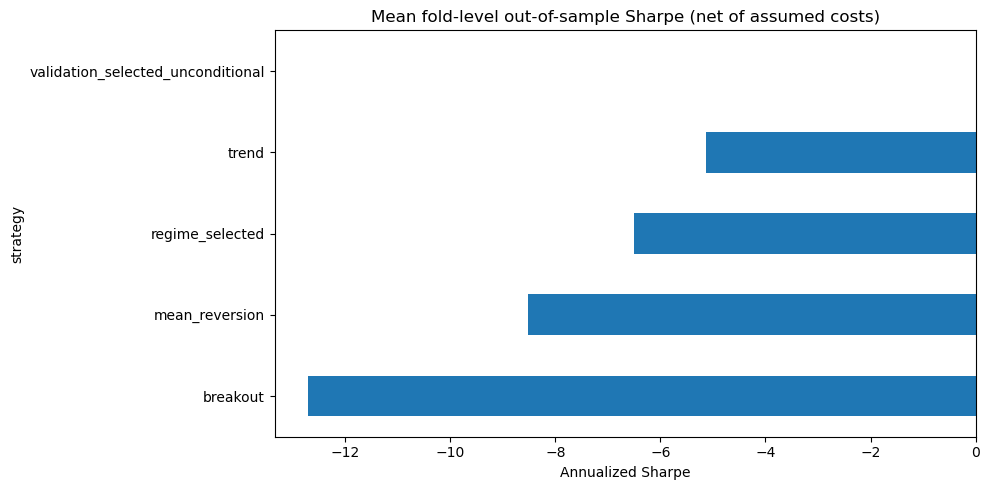

In [9]:
summary = results.groupby("strategy").agg(
    folds=("fold","nunique"),
    mean_fold_return_pct=("total_return_pct","mean"),
    median_fold_return_pct=("total_return_pct","median"),
    mean_annualized_sharpe=("annualized_sharpe","mean"),
    median_annualized_sharpe=("annualized_sharpe","median"),
    mean_max_drawdown_pct=("max_drawdown_pct","mean"),
    median_win_rate_pct=("win_rate_pct","median"),
    mean_profit_factor=("profit_factor","mean")
).sort_values("mean_annualized_sharpe", ascending=False)
display(summary.round(3))

fig, ax = plt.subplots(figsize=(10,5))
summary["mean_annualized_sharpe"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Mean fold-level out-of-sample Sharpe (net of assumed costs)")
ax.set_xlabel("Annualized Sharpe")
plt.tight_layout()
plt.show()

## 8. Diagnostics and sensitivity checks

Inspect whether the regime-selected approach repeatedly chooses the same strategy, whether some states are rare, and whether conclusions survive higher cost assumptions. The cost sensitivity reruns the fixed fold decisions only approximately from stored fold-level results; a full sensitivity study should rerun the entire validation selection at each cost level.

In [10]:
if not cluster_profiles.empty:
    display(cluster_profiles.groupby("state")[FEATURES + ["train_occupancy_pct"]].mean().round(4))

mapping_rows = []
for row in fold_mappings:
    for state, strat in row["state_to_strategy"].items():
        mapping_rows.append({"fold": row["fold"], "state": state, "selected_strategy": strat})
mapping_counts = pd.DataFrame(mapping_rows).groupby(["state","selected_strategy"]).size().unstack(fill_value=0)
display(mapping_counts)

# Sensitivity: show how the assumed one-way cost changes the net return of each
# fixed signal stream. This does not re-select strategies at each cost.
cost_sensitivity = []
for cost_bps in [0, 2, 5, 10, 20]:
    for strat in STRATEGIES:
        rr, _ = net_strategy_returns(signals[strat], gross_market_return, cost_bps=cost_bps)
        cost_sensitivity.append({"cost_bps_one_way": cost_bps, "strategy": strat,
                                 **summarize_returns(rr[valid_returns])})
cost_sensitivity = pd.DataFrame(cost_sensitivity)
display(cost_sensitivity.pivot(index="cost_bps_one_way", columns="strategy", values="total_return_pct").round(2))

,ret_5,momentum_20,volatility_20,rsi_14,ema_gap,atr_pct,train_occupancy_pct
state,,,,,,,
0,0.0021,0.0066,0.0026,55.7508,0.0015,0.0032,30.0070
1,-0.0028,-0.0107,0.0043,46.8810,-0.0027,0.0047,22.7865
2,-0.0029,-0.0099,0.0035,44.3513,-0.0026,0.0039,24.2489
3,0.0003,0.0003,0.0030,52.9912,-0.0001,0.0035,22.9575


selected_strategy,breakout,mean_reversion,trend
state,,,
0,2,4,23
1,1,6,22
2,1,7,21
3,2,6,21


strategy,breakout,mean_reversion,trend
cost_bps_one_way,,,
0,-0.44,-54.46,168.67
2,-84.70,-90.24,-56.65
5,-99.08,-99.03,-97.19
10,-99.99,-99.98,-99.97
20,-100.00,-100.00,-100.00


## 9. Export artifacts and interpretation checklist

The CSVs preserve fold-level evidence and state-to-strategy selections. Keep the configuration and assumptions with any presentation.

Before making a claim:
- Check that results are not dominated by one fold.
- Compare regime-selected results with the validation-selected unconditional strategy.
- Inspect drawdowns and profit factor, not Sharpe alone.
- Repeat the entire experiment at multiple cost assumptions, reselecting strategies only on validation data each time.
- Add a final untouched holdout or paper-trading period.
- Repeat on a tradable instrument (e.g., an appropriate NIFTY futures contract) with realistic contract rolls, brokerage, taxes, slippage, and position sizing before discussing deployability.
- Treat a positive historical result as a hypothesis, not proof of future returns.

In [11]:
OUT_DIR = Path("research/results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT_DIR / "walk_forward_fold_results.csv", index=False)
summary.to_csv(OUT_DIR / "walk_forward_summary.csv")
mapping_df.to_json(OUT_DIR / "walk_forward_strategy_mappings.json", orient="records", indent=2)
cluster_profiles.to_csv(OUT_DIR / "walk_forward_cluster_profiles.csv", index=False)
cost_sensitivity.to_csv(OUT_DIR / "walk_forward_cost_sensitivity.csv", index=False)
print("Saved outputs to:", OUT_DIR.resolve())

Saved outputs to: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\research\results
